# 01 · Data overview

What we train on while the Jolly Lane prototype collects data:

| Source | Role in her design |
|---|---|
| **NOAA USCRN hourly**, 10 northern Great Plains stations, 2016 to 2025 | Sensor inputs: soil moisture and soil temp (5/10/20 cm), air temp, RH, rain |
| **USDA SSURGO** (Soil Data Access API) at each station | Soil properties: sand/silt/clay, AWC, drainage class, bulk density |
| **NOAA National Blend of Models (NBM)**, archived via Open-Meteo Previous Runs, Oct 2024 onward | Real weather forecasts at 24/48/72 h lead, for the realistic test |
| **Cook Agronomy Farm** (WSU), daily, 2011 to 2012 | EC check for the NPK idea (notebook 06) |

All times are UTC.

In [1]:
# Setup: works locally (pip install -e . from the repo root) and on Google Colab
import sys, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:
    # Upload soilcast.zip to Google Drive (MyDrive) first
    from google.colab import drive
    drive.mount("/content/drive")
    !unzip -q -o /content/drive/MyDrive/soilcast.zip -d /content
    %cd /content/soilcast
    !pip install -q -e ".[gpu-trees]"
    sys.path.insert(0, "/content/soilcast/src")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from soilcast.config import PROCESSED, RAW, RESULTS
from soilcast.plotting import set_style, model_color, SERIES, MUTED
set_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
RESULTS.mkdir(exist_ok=True)

In [2]:
from soilcast import data
u = data.load_uscrn()
soils = data.load_soils()
nbm = data.load_forecasts()
coords = data.station_coords(u)
print(u.shape, "hourly rows;", u.station.nunique(), "stations;", u.time_utc.min(), "to", u.time_utc.max())

(876720, 18) hourly rows; 10 stations; 2016-01-01 01:00:00 to 2026-01-01 00:00:00


## Stations and their soils (SSURGO at 5 cm)

In [3]:
s5 = soils[soils.depth_cm == 5].set_index("station")
cov = u.groupby("station").agg(sm5_coverage=("SOIL_MOISTURE_5", lambda s: s.notna().mean()),
                               rain_mm_per_yr=("P_CALC", lambda s: s.sum() / 10),
                               mean_sm5=("SOIL_MOISTURE_5", "mean"))
tbl = coords.join(s5[["compname", "sandtotal_r", "claytotal_r", "awc_r", "dbthirdbar_r", "drainagecl"]]).join(cov)
tbl.round(3)

,LATITUDE,LONGITUDE,compname,sandtotal_r,claytotal_r,awc_r,dbthirdbar_r,drainagecl,sm5_coverage,rain_mm_per_yr,mean_sm5
station,,,,,,,,,,,
MT_Wolf_Point_29_ENE,48.31,-105.10,Farland,11.3,21.0,0.20,1.35,Well drained,0.539,308.55,0.196
ND_Jamestown_38_WSW,46.77,-99.48,Zahl,45.0,24.0,0.19,1.45,Well drained,0.704,521.77,0.134
ND_Medora_7_E,46.89,-103.38,Patent,36.0,21.0,0.17,1.15,Well drained,0.728,447.43,0.156
NE_Harrison_20_SSE,42.42,-103.74,Las Animas,62.9,12.0,0.20,1.48,Somewhat poorly drained,0.544,413.21,0.119
NE_Whitman_5_ENE,42.07,-101.44,Valentine,94.0,3.0,0.08,1.59,Excessively drained,0.791,462.29,0.061
SD_Aberdeen_35_WNW,45.71,-99.13,Williams,38.0,22.0,0.19,1.40,Well drained,0.720,479.27,0.183
SD_Buffalo_13_ESE,45.52,-103.30,Rhoades,40.0,24.0,0.21,1.40,Moderately well drained,0.685,390.94,0.216
SD_Pierre_24_S,44.02,-100.35,Lakoma,5.0,53.0,0.13,1.34,Well drained,0.787,515.76,0.254
SD_Sioux_Falls_14_NNE,43.73,-96.62,Nora,12.0,26.0,0.21,1.35,Well drained,0.724,735.98,0.276


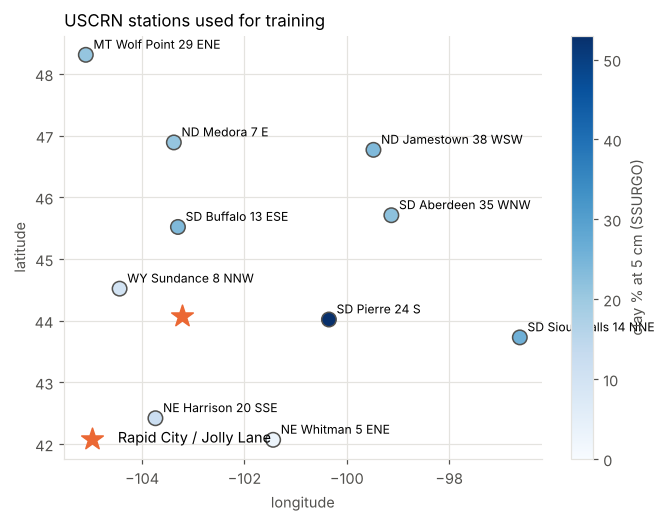

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(tbl.LONGITUDE, tbl.LATITUDE, c=tbl.claytotal_r, cmap="Blues", s=90, edgecolor=MUTED, vmin=0)
for st, r in tbl.iterrows():
    ax.annotate(st.replace("_", " "), (r.LONGITUDE, r.LATITUDE), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.scatter([-103.23], [44.08], marker="*", s=220, color="#eb6834", label="Rapid City / Jolly Lane")
plt.colorbar(sc, label="clay % at 5 cm (SSURGO)")
ax.set(xlabel="longitude", ylabel="latitude", title="USCRN stations used for training")
ax.legend(loc="lower left");

## When is soil moisture available?
USCRN moisture probes are dielectric sensors; frozen soil reads wrong and is mostly flagged missing. Our models only cover unfrozen soil (roughly April to November).

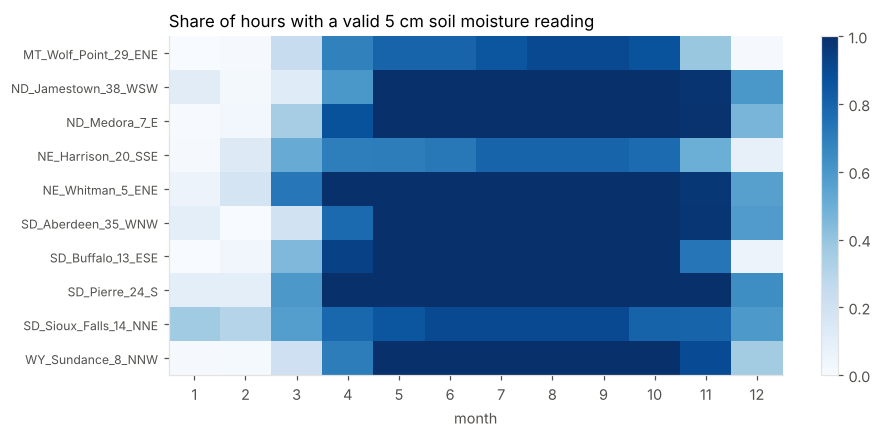

In [5]:
m = u.assign(month=u.time_utc.dt.month).groupby(["station", "month"]).SOIL_MOISTURE_5.apply(lambda s: s.notna().mean()).unstack()
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(m.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(m)), m.index, fontsize=8); ax.set_xticks(range(12), range(1, 13))
ax.set(xlabel="month", title="Share of hours with a valid 5 cm soil moisture reading"); ax.grid(False)
plt.colorbar(im);

## One growing season up close (SD Buffalo, 2023)

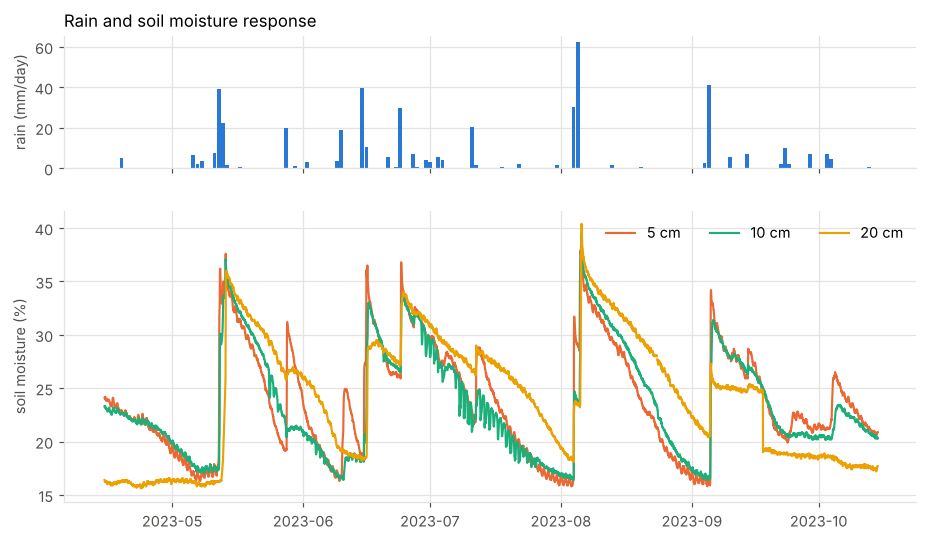

In [6]:
b = u[(u.station == "SD_Buffalo_13_ESE") & (u.time_utc >= "2023-04-15") & (u.time_utc < "2023-10-15")]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [1, 2.2]})
daily = b.set_index("time_utc").P_CALC.resample("D").sum()
a1.bar(daily.index, daily.values, width=0.9, color=SERIES[0]); a1.set(ylabel="rain (mm/day)", title="Rain and soil moisture response")
for i, dep in enumerate((5, 10, 20)):
    a2.plot(b.time_utc, 100 * b[f"SOIL_MOISTURE_{dep}"], lw=1.4, color=SERIES[i + 1], label=f"{dep} cm")
a2.set(ylabel="soil moisture (%)"); a2.legend(ncol=3);

What to notice:
- Each rain makes a sharp jump, biggest at 5 cm, smaller and later at depth, then a slow curved dry-down. That shape drives the features in notebook 02.
- The daily sawtooth at 10 cm in midsummer: steps down by day, flat at night (plant water uptake follows sunlight; part may be sensor temperature sensitivity).
- Sudden drops with no rain (e.g. 20 cm in mid-September) look like sensor or installation artifacts. A QC step that flags these is worth adding before training on the Jolly Lane probe.

## How good are real forecasts? (NBM vs what actually happened)
`fc_precip_24h` is the rain total over the next 24 h. In the perfect-forecast tables it's observed rain; in the NBM tables it comes from the forecast issued about 24 h earlier.

24 h rain: correlation 0.62, MAE 1.62 mm
>= 5 mm events: hit rate (POD) 0.64, false alarm ratio 0.44, CSI 0.43
air temp MAE 0.93 C, RH MAE 5.0 %


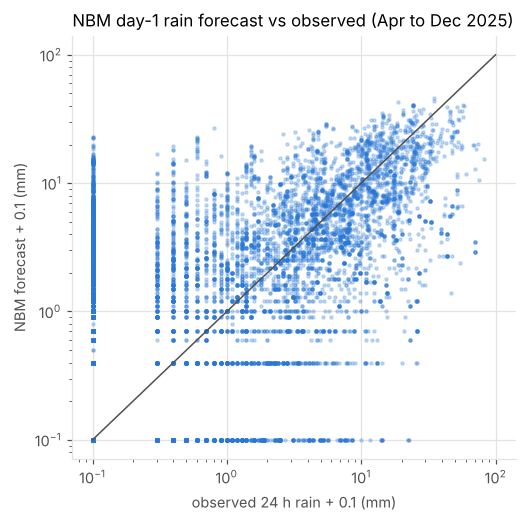

In [7]:
p = pd.read_parquet(PROCESSED / "features_5cm_perfect.parquet")
n = pd.read_parquet(PROCESSED / "features_5cm_nbm.parquet")
m = p[["station", "time_utc", "fc_precip_24h", "fc_air_t_mean_24h", "fc_rh_mean_24h"]].merge(
    n[["station", "time_utc", "fc_precip_24h", "fc_air_t_mean_24h", "fc_rh_mean_24h"]], on=["station", "time_utc"], suffixes=("_obs", "_nbm")).dropna()
m = m[m.time_utc >= "2025-04-01"]
obs, fc = m.fc_precip_24h_obs, m.fc_precip_24h_nbm
hit, miss = ((obs >= 5) & (fc >= 5)).sum(), ((obs >= 5) & (fc < 5)).sum()
fa = ((obs < 5) & (fc >= 5)).sum()
print(f"24 h rain: correlation {obs.corr(fc):.2f}, MAE {np.mean(np.abs(obs - fc)):.2f} mm")
print(f">= 5 mm events: hit rate (POD) {hit / (hit + miss):.2f}, false alarm ratio {fa / (hit + fa):.2f}, CSI {hit / (hit + miss + fa):.2f}")
print(f"air temp MAE {np.mean(np.abs(m.fc_air_t_mean_24h_obs - m.fc_air_t_mean_24h_nbm)):.2f} C, "
      f"RH MAE {np.mean(np.abs(m.fc_rh_mean_24h_obs - m.fc_rh_mean_24h_nbm)):.1f} %")
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(obs + 0.1, fc + 0.1, s=4, alpha=0.25, color=SERIES[0])
ax.plot([0.1, 100], [0.1, 100], color=MUTED, lw=1)
ax.set(xscale="log", yscale="log", xlabel="observed 24 h rain + 0.1 (mm)", ylabel="NBM forecast + 0.1 (mm)",
       title="NBM day-1 rain forecast vs observed (Apr to Dec 2025)");

Temperature and humidity forecasts are close to reality; rain is the weak link. Since rain also drives most of the soil moisture error (notebook 02), forecast quality sets the ceiling for model skill (notebook 04).